# Part A3 — Wide-and-Deep Architecture

This notebook evaluates the required wide-and-deep model against the A1 baseline.

The deep branch is the **A1-selected MLP**, while the wide branch is a single linear layer. Their outputs are combined as

output= {MLP output} + lambda*{linear output}.

### A3 procedure

1. Search lambda in {0, 0.25, 0.5, 1, 2} using the original A1 train/validation split:
   - 2017–2020: training
   - 2021: validation
   - early stopping exactly as in A1.
2. Select the (lambda\) with the lowest **best validation RMSE**.
3. Retrain the selected wide-and-deep architecture on combined 2017–2021 data for the **10 epochs selected in A1**, using five seeds.
4. Evaluate each trained model once on the 2022 test set.
5. Report mean ± **sample SD** of test RMSE and \(R^2\), and compare against the A1 baseline results from Part A2.

## 1. Environment and project setup

In [22]:
from pathlib import Path
import sys
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader

ROOT = Path.cwd()
SRC = ROOT / "src"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from config import Config
from data import prepare_data
from parta_common import prepare_combined_data, calculate_rmse, evaluate_regression

DATA_PATH = ROOT / "hdb_price_prediction.csv"
A2_OUTPUT_DIR = ROOT / "outputs" / "A2"
OUTPUT_DIR = ROOT / "outputs" / "A3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Data exists:", DATA_PATH.exists())

Project root: d:\NTU\26sem1\SC4001\housing_baseline_data\hdb-price-prediction-assignment-main
Data exists: True


### Environment verification

Part A3 is intended to run with the same project `.venv` and kernel as Parts A1 and A2.  
Before the final ZIP is prepared, the Python executable and package versions printed here should match the earlier notebooks.

In [23]:
from importlib.metadata import version as package_version

python_executable = Path(sys.executable).resolve()
project_venv = (ROOT / ".venv").resolve()

print("Python executable:", python_executable)
print("Python version:", sys.version.split()[0])
print("Project .venv:", project_venv)
print("Using project .venv:", str(project_venv).lower() in str(python_executable).lower())

for package in ["torch", "ray", "pandas", "numpy", "matplotlib"]:
    try:
        print(f"{package}: {package_version(package)}")
    except Exception:
        print(f"{package}: not installed")

Python executable: D:\NTU\26sem1\SC4001\housing_baseline_data\hdb-price-prediction-assignment-main\.venv\Scripts\python.exe
Python version: 3.12.14
Project .venv: D:\NTU\26sem1\SC4001\housing_baseline_data\hdb-price-prediction-assignment-main\.venv
Using project .venv: True
torch: 2.13.0
ray: 2.58.0
pandas: 3.0.5
numpy: 2.5.2
matplotlib: 3.11.1


## 2. Fixed A1 settings and A2 baseline outputs

Only \(\lambda\) is tuned in A3. The A1 architecture and training settings remain fixed.

The five-seed A1 baseline results are loaded from Part A2 rather than retrained, so the A3 comparison uses exactly the same baseline runs.

In [24]:
HIDDEN_WIDTH = 256
EMBEDDING_DIM = 2
A1_NUM_EPOCHS = 10

SELECTION_SEED = 42
SEEDS = [42, 43, 44, 45, 46]
LAMBDA_VALUES = [0, 0.25, 0.5, 1, 2]

A2_RESULTS_PATH = A2_OUTPUT_DIR / "A2_seed_level_results.csv"
A2_HISTORY_PATH = A2_OUTPUT_DIR / "A2_training_rmse_history.csv"

if not A2_RESULTS_PATH.exists() or not A2_HISTORY_PATH.exists():
    raise FileNotFoundError(
        "Part A2 output files were not found. Run PartA2_final.ipynb first so "
        "outputs/A2/A2_seed_level_results.csv and "
        "outputs/A2/A2_training_rmse_history.csv exist."
    )

a2_results = pd.read_csv(A2_RESULTS_PATH)
a2_history = pd.read_csv(A2_HISTORY_PATH)

baseline_results = (
    a2_results[a2_results["variant"] == "baseline"]
    .sort_values("seed")
    .reset_index(drop=True)
)

baseline_history = a2_history[a2_history["variant"] == "baseline"].copy()

print("A1 hidden width:", HIDDEN_WIDTH)
print("A1 embedding dimension:", EMBEDDING_DIM)
print("A1 final training epochs:", A1_NUM_EPOCHS)
print("Lambda candidates:", LAMBDA_VALUES)
print("Seeds:", SEEDS)
print("\nLoaded A2 baseline results:")
display(baseline_results)

A1 hidden width: 256
A1 embedding dimension: 2
A1 final training epochs: 10
Lambda candidates: [0, 0.25, 0.5, 1, 2]
Seeds: [42, 43, 44, 45, 46]

Loaded A2 baseline results:


,variant,seed,test_rmse,test_r2
0,baseline,42,103070.765625,0.633526
1,baseline,43,98039.132812,0.668433
2,baseline,44,111031.429688,0.574730
3,baseline,45,95936.171875,0.682505
4,baseline,46,97047.531250,0.675106


## 3. Wide-and-deep architecture

The concatenated input has

\[
4 * 2 + 6 = 14
\]

dimensions.

The two parallel branches are:

- **Deep branch:** `14 → 256 → 1`, with LayerNorm and ReLU exactly as selected in A1.
- **Wide branch:** one `Linear(14 → 1)` layer.

The final standardised prediction is

hat_y = hat_y_deep + lambda*hat_y_wide.

When lambda=0, the wide branch contributes nothing, so the model should reproduce the selected A1 deep model. This provides a useful sanity check.

In [25]:
class WideDeepModel(nn.Module):
    def __init__(
        self,
        cardinalities,
        target_mean,
        target_std,
        config,
        lambda_value
    ):
        super().__init__()

        self.embeddings = nn.ModuleList(
            nn.Embedding(cardinality, width)
            for cardinality, width in zip(
                cardinalities,
                config.embedding_dims
            )
        )

        input_width = (
            sum(config.embedding_dims)
            + len(config.continuous_features)
        )

        # A1-selected deep branch
        self.deep = nn.Sequential(
            nn.Linear(input_width, config.hidden_width),
            nn.LayerNorm(config.hidden_width),
            nn.ReLU(),
            nn.Linear(config.hidden_width, 1)
        )

        # New wide branch
        rng_state = torch.get_rng_state()
        self.wide = nn.Linear(input_width, 1)
        torch.set_rng_state(rng_state)

        self.lambda_value = float(lambda_value)
        self.target_mean = target_mean
        self.target_std = target_std

    def forward(self, categorical, continuous):
        embedded = [
            embedding(categorical[:, index])
            for index, embedding in enumerate(self.embeddings)
        ]

        features = torch.cat(
            embedded + [continuous],
            dim=1
        )

        deep_output = self.deep(features).squeeze(1)
        wide_output = self.wide(features).squeeze(1)

        return deep_output + self.lambda_value * wide_output

    def predict_price(self, categorical, continuous):
        return (
            self(categorical, continuous)
            * self.target_std
            + self.target_mean
        )

In [26]:
# Inspect the selected wide-and-deep parameter count.
parameter_check_config = Config(
    seed=SELECTION_SEED,
    hidden_width=HIDDEN_WIDTH,
    embedding_dims=(EMBEDDING_DIM,) * 4
)

parameter_check_data = prepare_data(
    DATA_PATH,
    parameter_check_config
)

parameter_check_model = WideDeepModel(
    parameter_check_data["cardinalities"],
    parameter_check_data["target_mean"],
    parameter_check_data["target_std"],
    parameter_check_config,
    lambda_value=1
)

wide_deep_params = sum(
    p.numel()
    for p in parameter_check_model.parameters()
    if p.requires_grad
)

wide_branch_params = sum(
    p.numel()
    for p in parameter_check_model.wide.parameters()
    if p.requires_grad
)

print("Wide-and-deep trainable parameters:", wide_deep_params)
print("Parameters added by the wide branch:", wide_branch_params)

Wide-and-deep trainable parameters: 4828
Parameters added by the wide branch: 15


## 4. Search for the optimal λ

The λ search uses the same A1 model-selection split and early-stopping rule:

- **2017–2020:** training
- **2021:** validation
- Adam optimiser
- maximum 20 epochs
- patience 4
- minimum improvement `1e-4`
- seed 42

Only λ changes between runs.

In [27]:
def train_wide_deep_selection(lambda_value, seed=SELECTION_SEED, verbose=False):
    config = Config(
        seed=seed,
        hidden_width=HIDDEN_WIDTH,
        embedding_dims=(EMBEDDING_DIM,) * 4
    )

    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)

    data = prepare_data(DATA_PATH, config)

    model = WideDeepModel(
        data["cardinalities"],
        data["target_mean"],
        data["target_std"],
        config,
        lambda_value
    )

    train_loader = DataLoader(
        data["train"],
        batch_size=config.batch_size,
        shuffle=True
    )

    loss_function = nn.MSELoss()
    optimiser = torch.optim.Adam(
        model.parameters(),
        lr=config.learning_rate
    )

    best_validation_rmse = float("inf")
    best_weights = None
    best_epoch = 0
    epochs_without_improvement = 0

    train_rmse_history = []
    validation_rmse_history = []

    for epoch in range(1, config.max_epochs + 1):
        model.train()
        squared_error = 0.0
        row_count = 0

        for categorical, continuous, target in train_loader:
            optimiser.zero_grad()

            standard_prediction = model(
                categorical,
                continuous
            )

            standard_target = (
                target - model.target_mean
            ) / model.target_std

            loss = loss_function(
                standard_prediction,
                standard_target
            )

            loss.backward()
            optimiser.step()

            prediction = (
                standard_prediction.detach()
                * model.target_std
                + model.target_mean
            )

            squared_error += (
                (prediction - target)
                .square()
                .sum()
                .item()
            )

            row_count += len(target)

        train_rmse = (squared_error / row_count) ** 0.5

        validation_rmse = calculate_rmse(
            model,
            data["validation"],
            config.batch_size
        )

        train_rmse_history.append(train_rmse)
        validation_rmse_history.append(validation_rmse)

        if verbose:
            print(
                f"λ={lambda_value:<4} | "
                f"epoch {epoch:02d} | "
                f"train RMSE {train_rmse:,.2f} | "
                f"validation RMSE {validation_rmse:,.2f}"
            )

        if (
            best_weights is None
            or validation_rmse
            < best_validation_rmse
            - config.early_stopping_threshold
        ):
            best_validation_rmse = validation_rmse
            best_weights = copy.deepcopy(
                model.state_dict()
            )
            best_epoch = epoch
            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

            if (
                epochs_without_improvement
                == config.early_stopping_patience
            ):
                if verbose:
                    print(
                        f"Early stopping after epoch {epoch}"
                    )
                break

    model.load_state_dict(best_weights)

    return {
        "lambda": float(lambda_value),
        "best_epoch": best_epoch,
        "best_validation_rmse": best_validation_rmse,
        "train_rmse_history": train_rmse_history,
        "validation_rmse_history": validation_rmse_history
    }

In [28]:
lambda_search_results = []

for lambda_value in LAMBDA_VALUES:
    print(f"Running λ = {lambda_value}")

    result = train_wide_deep_selection(
        lambda_value=lambda_value,
        seed=SELECTION_SEED,
        verbose=False
    )

    lambda_search_results.append({
        "lambda": result["lambda"],
        "best_epoch": result["best_epoch"],
        "best_validation_rmse": result["best_validation_rmse"]
    })

    print(
        f"best epoch = {result['best_epoch']} | "
        f"best validation RMSE = "
        f"{result['best_validation_rmse']:,.2f}"
    )

lambda_search_df = (
    pd.DataFrame(lambda_search_results)
    .sort_values("best_validation_rmse")
    .reset_index(drop=True)
)

lambda_search_df

Running λ = 0
best epoch = 10 | best validation RMSE = 59,880.89
Running λ = 0.25
best epoch = 5 | best validation RMSE = 64,641.08
Running λ = 0.5
best epoch = 10 | best validation RMSE = 61,120.46
Running λ = 1
best epoch = 10 | best validation RMSE = 63,705.02
Running λ = 2
best epoch = 3 | best validation RMSE = 65,923.84


,lambda,best_epoch,best_validation_rmse
0,0.00,10,59880.894531
1,0.50,10,61120.464844
2,1.00,10,63705.023438
3,0.25,5,64641.078125
4,2.00,3,65923.843750


### λ = 0 sanity check

With λ = 0, the wide branch is multiplied by zero. The validation result should therefore closely reproduce the A1 selected deep model under the same seed and model-selection split.

In [29]:
A1_REFERENCE_VALIDATION_RMSE = 59880.89
A1_REFERENCE_BEST_EPOCH = 10

lambda_zero_row = (
    lambda_search_df[lambda_search_df["lambda"] == 0]
    .iloc[0]
)

print(
    "λ=0 best validation RMSE:",
    f'{lambda_zero_row["best_validation_rmse"]:,.2f}'
)

print(
    "A1 reference validation RMSE:",
    f"{A1_REFERENCE_VALIDATION_RMSE:,.2f}"
)

print(
    "Absolute difference:",
    f'{abs(lambda_zero_row["best_validation_rmse"] - A1_REFERENCE_VALIDATION_RMSE):,.2f}'
)

print(
    "λ=0 best epoch:",
    int(lambda_zero_row["best_epoch"])
)

print(
    "A1 reference best epoch:",
    A1_REFERENCE_BEST_EPOCH
)

λ=0 best validation RMSE: 59,880.89
A1 reference validation RMSE: 59,880.89
Absolute difference: 0.00
λ=0 best epoch: 10
A1 reference best epoch: 10


### Select the optimal λ

In [30]:
best_lambda_row = lambda_search_df.iloc[0]

BEST_LAMBDA = float(best_lambda_row["lambda"])
BEST_LAMBDA_VALIDATION_RMSE = float(
    best_lambda_row["best_validation_rmse"]
)
BEST_LAMBDA_SEARCH_EPOCH = int(
    best_lambda_row["best_epoch"]
)

print("Selected λ:", BEST_LAMBDA)
print(
    "Best validation RMSE:",
    f"{BEST_LAMBDA_VALIDATION_RMSE:,.2f}"
)
print(
    "Best epoch during λ search:",
    BEST_LAMBDA_SEARCH_EPOCH
)

# The final five-seed comparison keeps A1's selected 10-epoch
# training budget so the wide-and-deep model is compared fairly
# against the A1 baseline runs from Part A2.
FINAL_NUM_EPOCHS = A1_NUM_EPOCHS

print(
    "Epochs used for final five-seed comparison:",
    FINAL_NUM_EPOCHS
)

Selected λ: 0.0
Best validation RMSE: 59,880.89
Best epoch during λ search: 10
Epochs used for final five-seed comparison: 10


### Validation RMSE across λ values

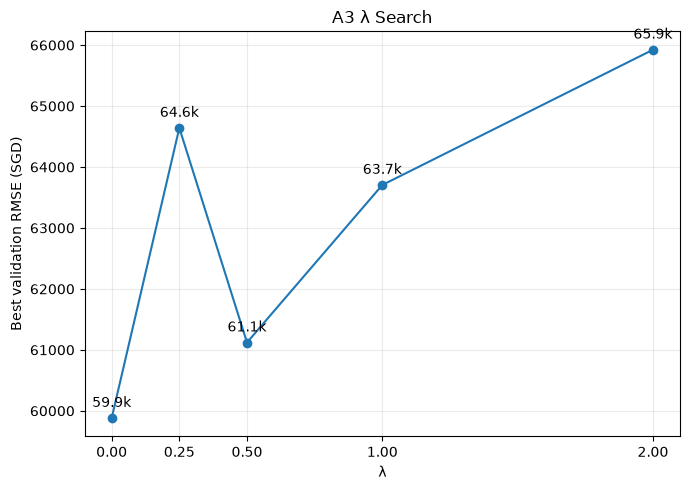

In [31]:
plot_search_df = lambda_search_df.sort_values("lambda")

plt.figure(figsize=(7, 5))

plt.plot(
    plot_search_df["lambda"],
    plot_search_df["best_validation_rmse"],
    marker="o"
)

for _, row in plot_search_df.iterrows():
    plt.annotate(
        f'{row["best_validation_rmse"] / 1000:.1f}k',
        (row["lambda"], row["best_validation_rmse"]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    )

plt.xlabel("λ")
plt.ylabel("Best validation RMSE (SGD)")
plt.title("A3 λ Search")
plt.xticks(LAMBDA_VALUES)
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "A3_lambda_search.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Five-seed evaluation of the selected wide-and-deep model

The selected λ is now evaluated with the same five seeds used in Part A2.

For a fair comparison with the A1 baseline:
- preprocessing is fit on combined 2017–2021 data;
- the selected A1 hidden width, embedding dimension, optimiser, learning rate and batch size are unchanged;
- every run is trained for **10 epochs**, matching the A1/A2 baseline training budget;
- the 2022 test set is evaluated once after training.

In [32]:
def train_wide_deep_final(
    seed,
    lambda_value=BEST_LAMBDA,
    verbose=False
):
    config = Config(
        seed=seed,
        hidden_width=HIDDEN_WIDTH,
        embedding_dims=(EMBEDDING_DIM,) * 4
    )

    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)

    data = prepare_combined_data(
        DATA_PATH,
        config
    )

    model = WideDeepModel(
        data["cardinalities"],
        data["target_mean"],
        data["target_std"],
        config,
        lambda_value
    )

    train_loader = DataLoader(
        data["combined"],
        batch_size=config.batch_size,
        shuffle=True
    )

    loss_function = nn.MSELoss()
    optimiser = torch.optim.Adam(
        model.parameters(),
        lr=config.learning_rate
    )

    train_rmse_history = []

    for epoch in range(1, FINAL_NUM_EPOCHS + 1):
        model.train()
        squared_error = 0.0
        row_count = 0

        for categorical, continuous, target in train_loader:
            optimiser.zero_grad()

            standard_prediction = model(
                categorical,
                continuous
            )

            standard_target = (
                target - model.target_mean
            ) / model.target_std

            loss = loss_function(
                standard_prediction,
                standard_target
            )

            loss.backward()
            optimiser.step()

            prediction = (
                standard_prediction.detach()
                * model.target_std
                + model.target_mean
            )

            squared_error += (
                (prediction - target)
                .square()
                .sum()
                .item()
            )

            row_count += len(target)

        train_rmse = (squared_error / row_count) ** 0.5
        train_rmse_history.append(train_rmse)

        if verbose:
            print(
                f"seed {seed} | "
                f"epoch {epoch:02d} | "
                f"train RMSE {train_rmse:,.2f}"
            )

    test_rmse, test_r2 = evaluate_regression(
        model,
        data["test"],
        config.batch_size
    )

    return {
        "seed": seed,
        "lambda": float(lambda_value),
        "model": model,
        "test_rmse": test_rmse,
        "test_r2": test_r2,
        "train_rmse_history": train_rmse_history
    }

In [33]:
wide_deep_results = []
wide_deep_training_histories = {}

for seed in SEEDS:
    result = train_wide_deep_final(
        seed=seed,
        lambda_value=BEST_LAMBDA,
        verbose=False
    )

    wide_deep_results.append({
        "seed": seed,
        "lambda": BEST_LAMBDA,
        "test_rmse": result["test_rmse"],
        "test_r2": result["test_r2"]
    })

    wide_deep_training_histories[seed] = (
        result["train_rmse_history"]
    )

    # Save the seed-42 selected wide-and-deep model for A4.
    if seed == 42:
        torch.save(
            result["model"].state_dict(),
            OUTPUT_DIR / "selected_wide_deep_seed42.pt"
        )

    print(
        f"seed {seed} | "
        f"test RMSE {result['test_rmse']:,.2f} | "
        f"test R² {result['test_r2']:.4f}"
    )

wide_deep_df = pd.DataFrame(
    wide_deep_results
)

wide_deep_df

seed 42 | test RMSE 103,070.77 | test R² 0.6335
seed 43 | test RMSE 98,039.13 | test R² 0.6684
seed 44 | test RMSE 111,031.43 | test R² 0.5747
seed 45 | test RMSE 95,936.17 | test R² 0.6825
seed 46 | test RMSE 97,047.53 | test R² 0.6751


,seed,lambda,test_rmse,test_r2
0,42,0.0,103070.765625,0.633526
1,43,0.0,98039.132812,0.668433
2,44,0.0,111031.429688,0.574730
3,45,0.0,95936.171875,0.682505
4,46,0.0,97047.531250,0.675106


## 6. Mean ± sample SD and comparison with the A1 baseline

The required five-seed summary is reported using the **sample standard deviation** (`ddof=1`). The A1 baseline values come directly from the Part A2 baseline runs.

In [34]:
def summarize_results(df, label):
    return {
        "model": label,
        "test_rmse_mean": df["test_rmse"].mean(),
        "test_rmse_sd": df["test_rmse"].std(ddof=1),
        "test_r2_mean": df["test_r2"].mean(),
        "test_r2_sd": df["test_r2"].std(ddof=1)
    }


comparison_summary_df = pd.DataFrame([
    summarize_results(
        baseline_results,
        "A1 baseline"
    ),
    summarize_results(
        wide_deep_df,
        f"Wide-and-deep (λ={BEST_LAMBDA:g})"
    )
])

baseline_rmse_mean = (
    comparison_summary_df
    .loc[
        comparison_summary_df["model"] == "A1 baseline",
        "test_rmse_mean"
    ]
    .iloc[0]
)

baseline_r2_mean = (
    comparison_summary_df
    .loc[
        comparison_summary_df["model"] == "A1 baseline",
        "test_r2_mean"
    ]
    .iloc[0]
)

comparison_summary_df["delta_rmse_vs_baseline"] = (
    comparison_summary_df["test_rmse_mean"]
    - baseline_rmse_mean
)

comparison_summary_df["delta_r2_vs_baseline"] = (
    comparison_summary_df["test_r2_mean"]
    - baseline_r2_mean
)

comparison_summary_df

,model,test_rmse_mean,test_rmse_sd,test_r2_mean,test_r2_sd,delta_rmse_vs_baseline,delta_r2_vs_baseline
0,A1 baseline,101025.00625,6223.857813,0.64686,0.044481,0.0,0.0
1,Wide-and-deep (λ=0),101025.00625,6223.857813,0.64686,0.044481,0.0,0.0


In [35]:
report_table = comparison_summary_df[["model"]].copy()

report_table["Test RMSE (mean ± SD)"] = (
    comparison_summary_df.apply(
        lambda row:
        f'{row["test_rmse_mean"]:,.0f} ± '
        f'{row["test_rmse_sd"]:,.0f}',
        axis=1
    )
)

report_table["Test R² (mean ± SD)"] = (
    comparison_summary_df.apply(
        lambda row:
        f'{row["test_r2_mean"]:.4f} ± '
        f'{row["test_r2_sd"]:.4f}',
        axis=1
    )
)

report_table["ΔRMSE vs baseline"] = (
    comparison_summary_df[
        "delta_rmse_vs_baseline"
    ].map(lambda value: f"{value:+,.0f}")
)

report_table["ΔR² vs baseline"] = (
    comparison_summary_df[
        "delta_r2_vs_baseline"
    ].map(lambda value: f"{value:+.4f}")
)

report_table

,model,Test RMSE (mean ± SD),Test R² (mean ± SD),ΔRMSE vs baseline,ΔR² vs baseline
0,A1 baseline,"101,025 ± 6,224",0.6469 ± 0.0445,+0,+0.0000
1,Wide-and-deep (λ=0),"101,025 ± 6,224",0.6469 ± 0.0445,+0,+0.0000


## 7. Paired seed-wise comparison

Because the wide-and-deep model and baseline use the same five seeds, a paired comparison shows whether the direction of the effect is consistent across seeds.

In [36]:
paired_df = (
    baseline_results[
        ["seed", "test_rmse", "test_r2"]
    ]
    .rename(columns={
        "test_rmse": "baseline_rmse",
        "test_r2": "baseline_r2"
    })
    .merge(
        wide_deep_df[
            ["seed", "test_rmse", "test_r2"]
        ].rename(columns={
            "test_rmse": "wide_deep_rmse",
            "test_r2": "wide_deep_r2"
        }),
        on="seed"
    )
)

paired_df["delta_rmse"] = (
    paired_df["wide_deep_rmse"]
    - paired_df["baseline_rmse"]
)

paired_df["delta_r2"] = (
    paired_df["wide_deep_r2"]
    - paired_df["baseline_r2"]
)

paired_df

,seed,baseline_rmse,baseline_r2,wide_deep_rmse,wide_deep_r2,delta_rmse,delta_r2
0,42,103070.765625,0.633526,103070.765625,0.633526,0.0,0.0
1,43,98039.132812,0.668433,98039.132812,0.668433,0.0,0.0
2,44,111031.429688,0.574730,111031.429688,0.574730,0.0,0.0
3,45,95936.171875,0.682505,95936.171875,0.682505,0.0,0.0
4,46,97047.531250,0.675106,97047.531250,0.675106,0.0,0.0


In [37]:
paired_summary_df = pd.DataFrame([{
    "mean_delta_rmse": paired_df["delta_rmse"].mean(),
    "sd_delta_rmse": paired_df["delta_rmse"].std(ddof=1),
    "mean_delta_r2": paired_df["delta_r2"].mean(),
    "sd_delta_r2": paired_df["delta_r2"].std(ddof=1),
    "wide_deep_better_rmse_seeds": int(
        (paired_df["delta_rmse"] < 0).sum()
    ),
    "wide_deep_better_r2_seeds": int(
        (paired_df["delta_r2"] > 0).sum()
    )
}])

paired_summary_df

,mean_delta_rmse,sd_delta_rmse,mean_delta_r2,sd_delta_r2,wide_deep_better_rmse_seeds,wide_deep_better_r2_seeds
0,0.0,0.0,0.0,0.0,0,0


## 8. Test RMSE across five seeds

Each small point is one seed. The diamond shows the five-seed mean and the error bar shows **±1 sample SD**.

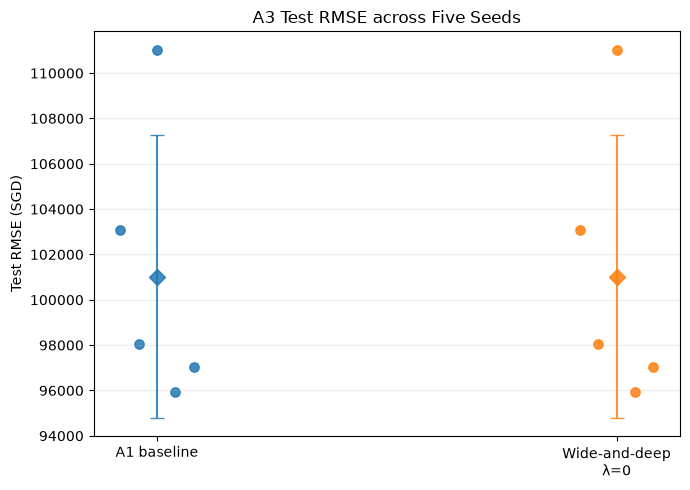

In [38]:
plot_models = [
    ("A1 baseline", baseline_results),
    (f"Wide-and-deep\nλ={BEST_LAMBDA:g}", wide_deep_df)
]

x_positions = np.arange(len(plot_models))
jitter = np.linspace(-0.08, 0.08, len(SEEDS))

plt.figure(figsize=(7, 5))

for x, (label, df) in zip(
    x_positions,
    plot_models
):
    values = (
        df.sort_values("seed")["test_rmse"]
        .to_numpy()
    )

    scatter = plt.scatter(
        x + jitter,
        values,
        s=45,
        alpha=0.85
    )

    plt.errorbar(
        x,
        values.mean(),
        yerr=values.std(ddof=1),
        fmt="D",
        markersize=8,
        capsize=5,
        linewidth=1.5,
        color=scatter.get_facecolor()[0]
    )

plt.xticks(
    x_positions,
    [label for label, _ in plot_models]
)

plt.ylabel("Test RMSE (SGD)")
plt.title("A3 Test RMSE across Five Seeds")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "A3_test_rmse_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 9. Test $R^2$ across five seeds

Each small point is one seed. The diamond shows the five-seed mean and the error bar shows **±1 sample SD**.

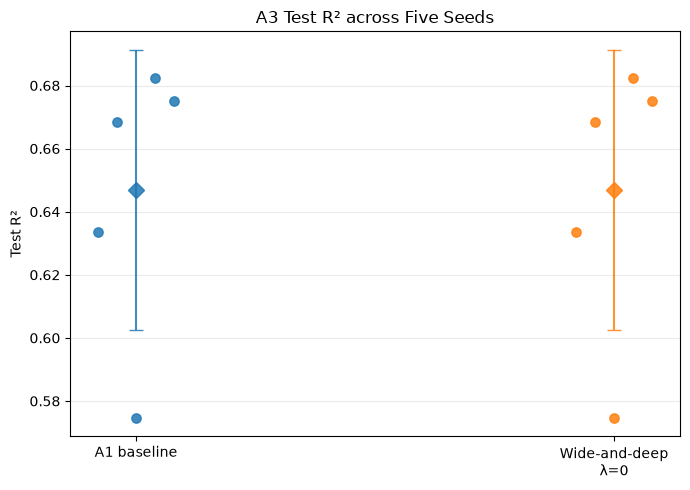

In [39]:
plt.figure(figsize=(7, 5))

for x, (label, df) in zip(
    x_positions,
    plot_models
):
    values = (
        df.sort_values("seed")["test_r2"]
        .to_numpy()
    )

    scatter = plt.scatter(
        x + jitter,
        values,
        s=45,
        alpha=0.85
    )

    plt.errorbar(
        x,
        values.mean(),
        yerr=values.std(ddof=1),
        fmt="D",
        markersize=8,
        capsize=5,
        linewidth=1.5,
        color=scatter.get_facecolor()[0]
    )

plt.xticks(
    x_positions,
    [label for label, _ in plot_models]
)

plt.ylabel("Test R²")
plt.title("A3 Test R² across Five Seeds")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "A3_test_r2_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 10. Training RMSE: baseline vs wide-and-deep

The baseline training histories are loaded from A2. The wide-and-deep histories are from the five A3 runs. Lines show the mean training RMSE and shaded bands show **±1 sample SD**.

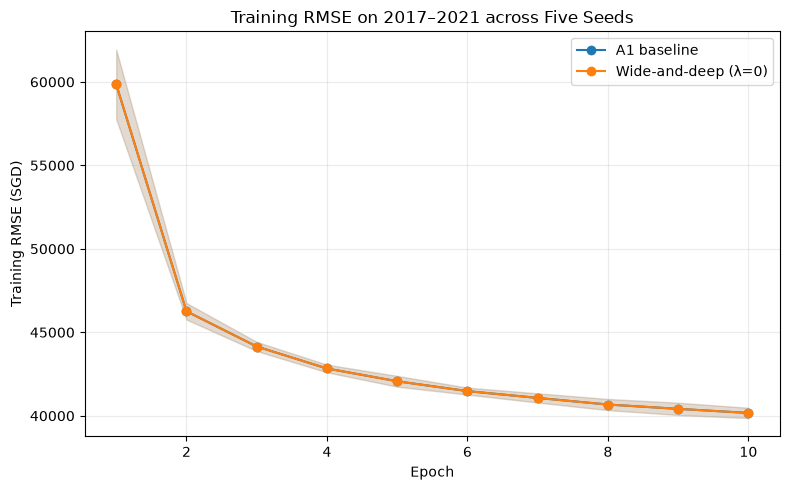

In [40]:
epochs = np.arange(1, FINAL_NUM_EPOCHS + 1)

baseline_history_matrix = np.array([
    (
        baseline_history[
            baseline_history["seed"] == seed
        ]
        .sort_values("epoch")["train_rmse"]
        .to_numpy()
    )
    for seed in SEEDS
])

wide_deep_history_matrix = np.array([
    wide_deep_training_histories[seed]
    for seed in SEEDS
])

plt.figure(figsize=(8, 5))

for label, history_matrix in [
    ("A1 baseline", baseline_history_matrix),
    (
        f"Wide-and-deep (λ={BEST_LAMBDA:g})",
        wide_deep_history_matrix
    )
]:
    mean_history = history_matrix.mean(axis=0)
    sd_history = history_matrix.std(
        axis=0,
        ddof=1
    )

    line, = plt.plot(
        epochs,
        mean_history,
        marker="o",
        label=label
    )

    plt.fill_between(
        epochs,
        mean_history - sd_history,
        mean_history + sd_history,
        alpha=0.15,
        color=line.get_color()
    )

plt.xlabel("Epoch")
plt.ylabel("Training RMSE (SGD)")
plt.title(
    "Training RMSE on 2017–2021 "
    "across Five Seeds"
)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "A3_training_rmse_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. Save A3 outputs

In [41]:
history_rows = []

for seed, history in wide_deep_training_histories.items():
    for epoch, train_rmse in enumerate(
        history,
        start=1
    ):
        history_rows.append({
            "seed": seed,
            "lambda": BEST_LAMBDA,
            "epoch": epoch,
            "train_rmse": train_rmse
        })

wide_deep_history_df = pd.DataFrame(
    history_rows
)

lambda_search_df.to_csv(
    OUTPUT_DIR / "A3_lambda_search.csv",
    index=False
)

wide_deep_df.to_csv(
    OUTPUT_DIR / "A3_seed_level_results.csv",
    index=False
)

comparison_summary_df.to_csv(
    OUTPUT_DIR / "A3_summary_mean_sd.csv",
    index=False
)

paired_df.to_csv(
    OUTPUT_DIR / "A3_paired_vs_baseline.csv",
    index=False
)

paired_summary_df.to_csv(
    OUTPUT_DIR / "A3_paired_summary.csv",
    index=False
)

wide_deep_history_df.to_csv(
    OUTPUT_DIR / "A3_training_rmse_history.csv",
    index=False
)

pd.DataFrame([{
    "selected_lambda": BEST_LAMBDA,
    "best_validation_rmse": BEST_LAMBDA_VALIDATION_RMSE,
    "lambda_search_best_epoch": BEST_LAMBDA_SEARCH_EPOCH,
    "final_training_epochs": FINAL_NUM_EPOCHS
}]).to_csv(
    OUTPUT_DIR / "A3_selected_configuration.csv",
    index=False
)

print("Saved A3 outputs to:", OUTPUT_DIR)
print(
    "Seed-42 wide-and-deep model saved as:",
    OUTPUT_DIR / "selected_wide_deep_seed42.pt"
)

Saved A3 outputs to: d:\NTU\26sem1\SC4001\housing_baseline_data\hdb-price-prediction-assignment-main\outputs\A3
Seed-42 wide-and-deep model saved as: d:\NTU\26sem1\SC4001\housing_baseline_data\hdb-price-prediction-assignment-main\outputs\A3\selected_wide_deep_seed42.pt


## 12. Interpretation guide for the report

Use the actual values produced above when writing the A3 discussion.

### Why the wide branch may help

The deep branch can model nonlinear relationships and feature interactions, while the additional linear branch gives the model a direct path for approximately additive effects. The final prediction combines both:

\[
\text{deep contribution} + \lambda \times \text{linear contribution}.
\]

A useful linear component can therefore reduce the burden on the MLP to represent simple trends. The additional direct path may also change optimisation because it provides a short route from the input features to the prediction.

### Evidence to examine

1. **λ search:** Does a non-zero λ achieve lower validation RMSE than λ = 0?
2. **Five-seed test results:** Does the selected wide-and-deep model improve mean test RMSE and/or mean \(R^2\) over the A1 baseline?
3. **Consistency:** Is the improvement present for most of the five matched seeds, or is the mean driven by one or two runs?
4. **Training curves:** Does wide-and-deep reach lower training RMSE faster, or does it mainly affect test performance?

If λ = 0 is best, the evidence suggests the added linear branch does not improve validation performance for this task. If a non-zero λ is best and the five-seed test results also improve consistently, the evidence is more supportive of the proposed mechanism.

### Limitation / confound

At least one limitation should be stated. Two important ones are:

- **λ is selected using seed 42 only.** The best λ may therefore be somewhat seed-specific; a nested multi-seed validation procedure would be more robust but substantially more expensive.
- **The wide-and-deep model has extra trainable parameters.** Any performance difference is not caused purely by “being linear + nonlinear”; it also changes model capacity, although the extra wide branch is small.

The time-based split is another important context: training uses 2017–2021 while testing uses 2022, so temporal distribution shift can affect both architectures.